In [9]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files
from google.colab.patches import cv2_imshow

Saving pisang.webp to pisang.webp


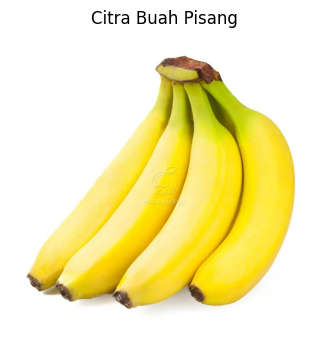

In [10]:
# Upload gambar
uploaded = files.upload()

# Membaca gambar
nama_file = list(uploaded.keys())[0]
gambar = cv2.imread(nama_file)

# Mengubah format BGR menjadi RGB
img_rgb = cv2.cvtColor(gambar, cv2.COLOR_BGR2RGB)

# Menampilkan gambar
plt.figure(figsize=(6, 4))
plt.imshow(img_rgb)
plt.title("Citra Buah Pisang")
plt.axis('off')
plt.show()

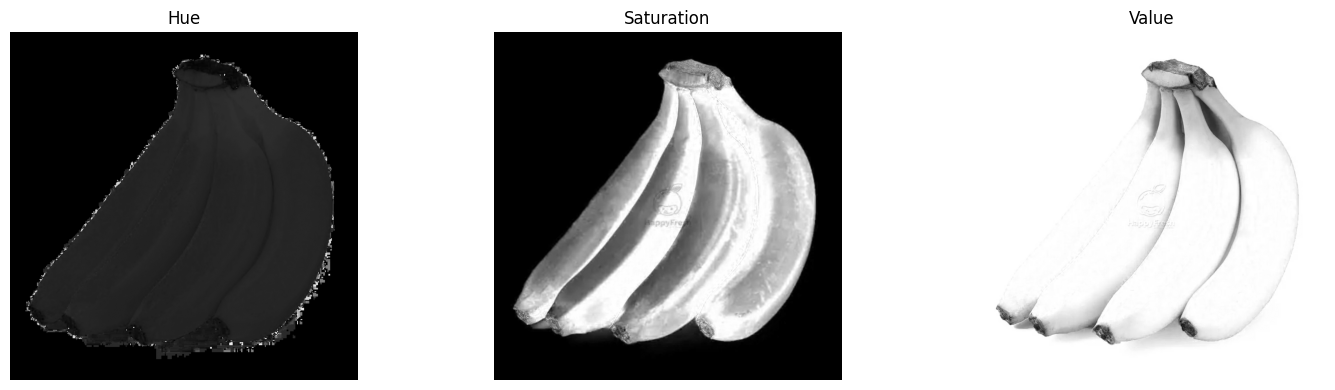

In [11]:
# Konversi RGB ke HSV
img_hsv = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2HSV)

#Menampilkan masng-masing kanal HSV
h, s, v = cv2.split(img_hsv)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(h, cmap='gray')
plt.title('Hue')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(s, cmap='gray')
plt.title('Saturation')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(v, cmap='gray')
plt.title('Value')
plt.axis('off')

plt.tight_layout()
plt.show()

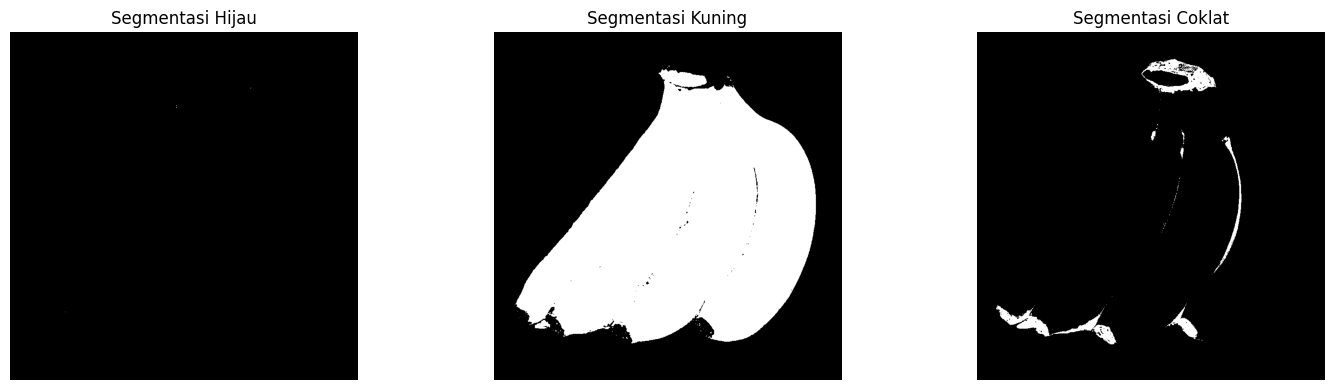

In [12]:
# Segmentasi warna hijau
lower_green = np.array([35, 40, 40])
upper_green = np.array([85, 255, 255])
mask_green = cv2.inRange(img_hsv, lower_green, upper_green)

# Segmentasi warna kuning
lower_yellow = np.array([20, 70, 60])
upper_yellow = np.array([35, 255, 255])
mask_yellow = cv2.inRange(img_hsv, lower_yellow, upper_yellow)

# Segmentasi warna cokelat
lower_brown = np.array([5, 50, 20])
upper_brown = np.array([25, 255, 180])
mask_brown = cv2.inRange(img_hsv, lower_brown, upper_brown)

#Visualisasi hasil segmentasi
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask_green, cmap='gray')
plt.title('Segmentasi Hijau')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_yellow, cmap='gray')
plt.title('Segmentasi Kuning')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_brown, cmap='gray')
plt.title('Segmentasi Coklat')
plt.axis('off')

plt.tight_layout()
plt.show()

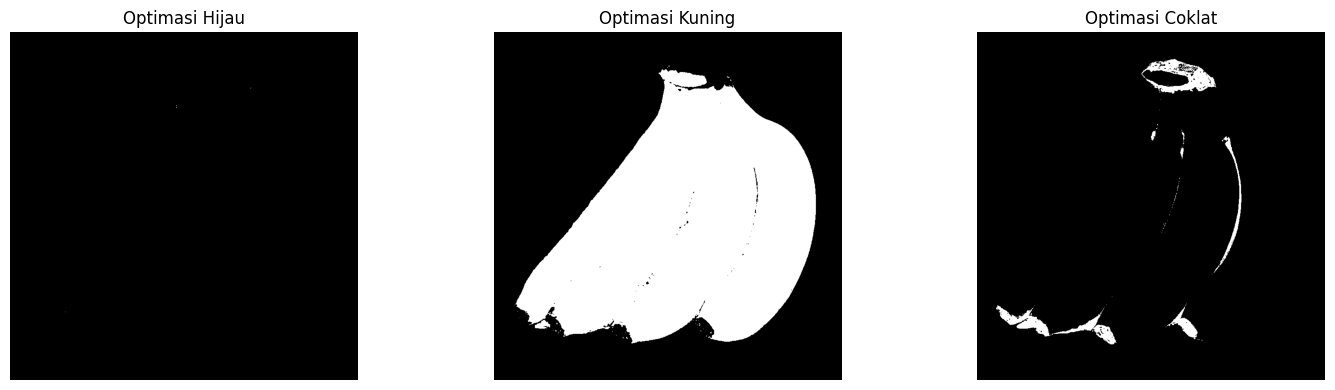

In [13]:
#@title Interactive HSV Color Masking { run: "auto" }
# Gunakan slider di sebelah kanan untuk menyesuaikan ambang batas HSV secara langsung

# Ambang batas Hijau
h_min_green = 35 #@param {type:"slider", min:0, max:180, step:1}
s_min_green = 40 #@param {type:"slider", min:0, max:255, step:1}
v_min_green = 40 #@param {type:"slider", min:0, max:255, step:1}
h_max_green = 85 #@param {type:"slider", min:0, max:180, step:1}
s_max_green = 255 #@param {type:"slider", min:0, max:255, step:1}
v_max_green = 255 #@param {type:"slider", min:0, max:255, step:1}

# Ambang batas Kuning
h_min_yellow = 20 #@param {type:"slider", min:0, max:180, step:1}
s_min_yellow = 70 #@param {type:"slider", min:0, max:255, step:1}
v_min_yellow = 60 #@param {type:"slider", min:0, max:255, step:1}
h_max_yellow = 35 #@param {type:"slider", min:0, max:180, step:1}
s_max_yellow = 255 #@param {type:"slider", min:0, max:255, step:1}
v_max_yellow = 255 #@param {type:"slider", min:0, max:255, step:1}

# Ambang batas Cokelat
h_min_brown = 5 #@param {type:"slider", min:0, max:180, step:1}
s_min_brown = 50 #@param {type:"slider", min:0, max:255, step:1}
v_min_brown = 20 #@param {type:"slider", min:0, max:255, step:1}
h_max_brown = 25 #@param {type:"slider", min:0, max:180, step:1}
s_max_brown = 255 #@param {type:"slider", min:0, max:255, step:1}
v_max_brown = 180 #@param {type:"slider", min:0, max:255, step:1}

# Menerapkan Masking berdasarkan slider
lower_green_opt = np.array([h_min_green, s_min_green, v_min_green])
upper_green_opt = np.array([h_max_green, s_max_green, v_max_green])
mask_green_opt = cv2.inRange(img_hsv, lower_green_opt, upper_green_opt)

lower_yellow_opt = np.array([h_min_yellow, s_min_yellow, v_min_yellow])
upper_yellow_opt = np.array([h_max_yellow, s_max_yellow, v_max_yellow])
mask_yellow_opt = cv2.inRange(img_hsv, lower_yellow_opt, upper_yellow_opt)

lower_brown_opt = np.array([h_min_brown, s_min_brown, v_min_brown])
upper_brown_opt = np.array([h_max_brown, s_max_brown, v_max_brown])
mask_brown_opt = cv2.inRange(img_hsv, lower_brown_opt, upper_brown_opt)

# Visualisasi Hasil Optimasi
plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
plt.imshow(mask_green_opt, cmap='gray')
plt.title('Optimasi Hijau')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_yellow_opt, cmap='gray')
plt.title('Optimasi Kuning')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(mask_brown_opt, cmap='gray')
plt.title('Optimasi Coklat')
plt.axis('off')

plt.tight_layout()
plt.show()

In [19]:
# Menghitung jmlah piksel setiap warna
hijau = np.count_nonzero(mask_green)
kuning = np.count_nonzero(mask_yellow)
cokelat = np.count_nonzero(mask_brown)

# Jumlahkan untuk mencari total piksel buah
total_pixel = hijau + kuning + cokelat

# Mennghitung persentase
persentase_hijau = (hijau / total_pixel) * 100
persentase_kuning = (kuning / total_pixel) * 100
persentase_cokelat = (cokelat / total_pixel) * 100

print(f"Persentase Hijau: {persentase_hijau:.2f}%")
print(f"Persentase Kuning: {persentase_kuning:.2f}%")
print(f"Persentase Coklat: {persentase_cokelat:.2f}%")


Persentase Hijau: 0.00%
Persentase Kuning: 94.82%
Persentase Coklat: 5.18%


In [15]:
# Klasifikasi berdasarkan warna dominan
warna = {
    "Mentah (hijau)": persentase_hijau,
    "Matang (Kuning)": persentase_kuning,
    "Terlalu Matang (cokelat)": persentase_cokelat
}

hasil = max(warna, key=warna.get)
print("Hasil Analisis Citra")
print(f"Tingkat Kematangan: {hasil}")
print(f"Persentase Warna Dominan: {warna[hasil]:.2f}%")

Hasil Analisis Citra
Tingkat Kematangan: Matang (Kuning)
Persentase Warna Dominan: 42.10%


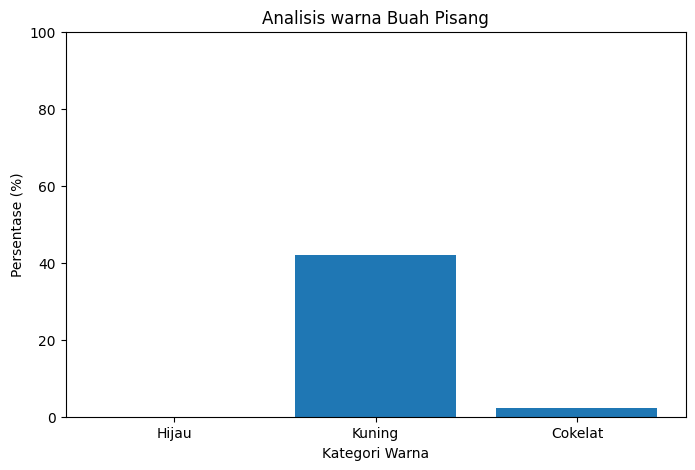

In [16]:
# Grafik persentase warna
labels = ['Hijau', 'Kuning', 'Cokelat']
values = [persentase_hijau, persentase_kuning, persentase_cokelat]

plt.figure(figsize=(8, 5))
plt.bar(labels, values)
plt.title("Analisis warna Buah Pisang")
plt.xlabel("Kategori Warna")
plt.ylabel("Persentase (%)")
plt.ylim(0, 100)
plt.show()